In [1]:
import json
import pandas as pd
import tensorflow as tf

# 1. GPU (GTX 1050 Ti) の認識確認とVRAM枯渇防止設定
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ GPU認識成功: {len(gpus)} 台のGPUが利用可能です -> {gpus[0].name}")
    except RuntimeError as e:
        print(e)
else:
    print("⚠️ GPUが認識されていません。CPUモードで動作します。")

# 2. 抽出したWebハニーポットログ (22MB) の読み込み
file_path = '/tf/notebooks/dataset/web_attacks_clean.json'
records = []

with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        try:
            data = json.loads(line)
            record = {
                'timestamp': data.get('timestamp'),
                'event_type': data.get('event_type'),
                'src_ip': data.get('src_ip'),
                'src_port': data.get('src_port'),
                'dest_port': data.get('dest_port'),
                'proto': data.get('proto'),
                'http_method': data.get('http', {}).get('http_method'),
                'url': data.get('http', {}).get('url'),
                'user_agent': data.get('http', {}).get('http_user_agent'),
                'status': data.get('http', {}).get('status'),
                'length': data.get('http', {}).get('length'),
                'signature': data.get('alert', {}).get('signature'),
                'category': data.get('alert', {}).get('category'),
                'severity': data.get('alert', {}).get('severity')
            }
            records.append(record)
        except json.JSONDecodeError:
            continue

df = pd.DataFrame(records)
print(f"\n📊 読み込み完了: 総レコード数 {len(df):,} 件")
print("\n--- イベント種別ごとの内訳 ---")
print(df['event_type'].value_counts())

print("\n--- 最も多く狙われたURL Top 10 ---")
print(df['url'].value_counts().head(10))

print("\n--- 検知された攻撃シグネチャ一覧 ---")
print(df['signature'].value_counts().dropna())

I0000 00:00:1793267481.931698      33 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


✅ GPU認識成功: 1 台のGPUが利用可能です -> /physical_device:GPU:0

📊 読み込み完了: 総レコード数 38,255 件

--- イベント種別ごとの内訳 ---
event_type
http       37777
alert        242
anomaly      236
Name: count, dtype: int64

--- 最も多く狙われたURL Top 10 ---
url
/v1/decisions/stream?additional_pull=false&community_pull=false&startup=true    36101
/                                                                                 403
/SDK/webLanguage                                                                  104
/favicon.ico                                                                       80
/libhtp::request_uri_not_seen                                                      48
http://a7x.overflow.biz/hachk.php                                                  32
/login                                                                             32
httpbin.org:443                                                                    30
/.well-known/security.txt                                                          10
/mcp  

🧹 クレンジング完了: 内部通信を除外し、純粋な外部HTTP通信 1,676 件を抽出しました。

--- 🎯 真の標的URL Top 15 (外部からのアクセスのみ) ---
url
/                                    400
/favicon.ico                          80
/SDK/webLanguage                      52
                                      36
http://a7x.overflow.biz/hachk.php     32
/login                                32
httpbin.org:443                       30
/libhtp::request_uri_not_seen         24
/.well-known/security.txt             10
/mcp                                   9
/sse                                   9
/mcp/                                  8
/api/mcp                               8
/zc?action=getInfo                     8
/.env                                  6
Name: count, dtype: int64

🚀 GTX 1050 Ti でAutoencoderの学習を開始します（EarlyStopping適用）...


I0000 00:00:1793283564.325856     117 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6115__.7


✅ 学習完了！（最適エポック数: 50 Epochs）

🚨 AI異常検知結果: 閾値 (3.15) を超えた高リスク通信 80 件を検出

--- 🤖 AIが「最も異常度が高い」と判定した攻撃通信 Top 15 ---
 anomaly_score       method_short              url_short  status                 ua_short
         87.59               EFDK                      /   405.0 Mozilla/5.0 (compatible)
         81.58 \xbb   user if                          400.0                      NaN
         70.08               LRAN                      /   405.0 Mozilla/5.0 (compatible)
         62.02      #9b         stackoverflowcom        NaN                      NaN
         61.94               SNDV                      /   405.0 Mozilla/5.0 (compatible)
         61.12               FPKM                      /   405.0 Mozilla/5.0 (compatible)
         61.02               OFPQ                      /   405.0 Mozilla/5.0 (compatible)
         60.47 \xf0|\x8a\xf0}\xa                          400.0                      NaN
         55.96               ZVFM                      /   405.0 Mozilla/5.0 (c

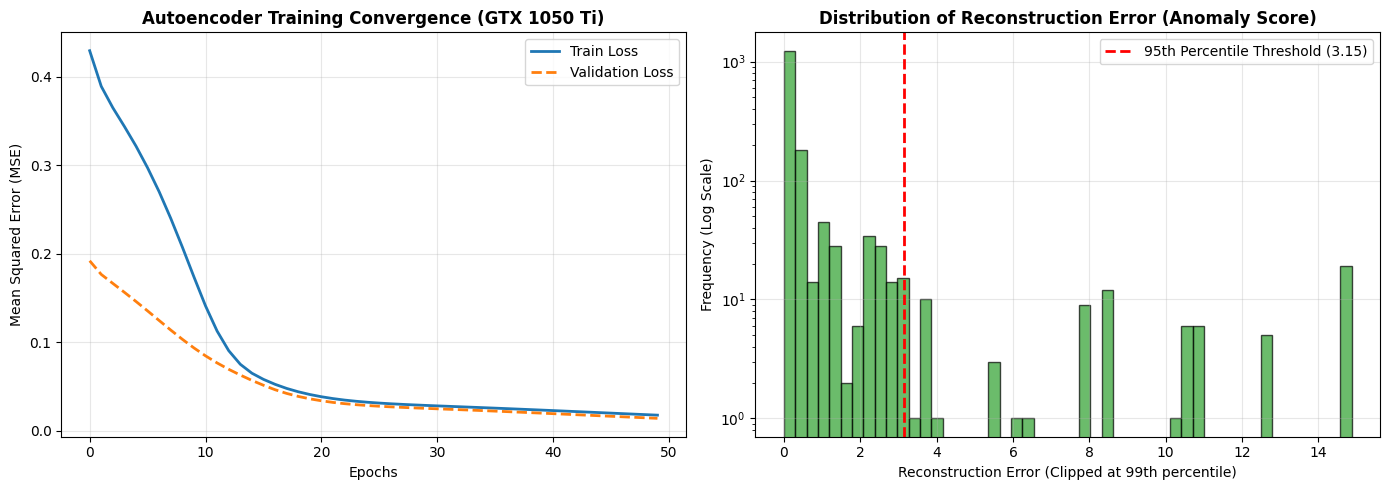


💾 改善版グラフを '/tf/notebooks/ai_anomaly_detection_result.png' として上書き保存しました！


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

# 乱数シードの固定（再現性の担保）
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# 1. データクレンジング（CrowdSec内部通信の除外）
# ==========================================
df_http = df[df['event_type'] == 'http'].copy()
df_http['url'] = df_http['url'].fillna('')

# CrowdSecのローカルAPIポーリング通信を除外
df_ext = df_http[~df_http['url'].str.startswith('/v1/decisions/stream')].copy()

print(f"🧹 クレンジング完了: 内部通信を除外し、純粋な外部HTTP通信 {len(df_ext):,} 件を抽出しました。\n")
print("--- 🎯 真の標的URL Top 15 (外部からのアクセスのみ) ---")
print(df_ext['url'].value_counts().head(15))

# ==========================================
# 2. 特徴量エンジニアリング
# ==========================================
df_ext['url_len'] = df_ext['url'].apply(len)
df_ext['special_chars'] = df_ext['url'].apply(lambda x: sum(not c.isalnum() for c in x))
df_ext['has_http_in_url'] = df_ext['url'].apply(lambda x: 1 if 'http' in x.lower() else 0)
df_ext['ua_len'] = df_ext['user_agent'].fillna('').apply(len)
df_ext['status_code'] = df_ext['status'].fillna(0).astype(float)
df_ext['res_length'] = df_ext['length'].fillna(0).astype(float)

methods = pd.get_dummies(df_ext['http_method'].fillna('UNKNOWN'), prefix='method', dtype=float)

feature_cols = ['url_len', 'special_chars', 'has_http_in_url', 'ua_len', 'status_code', 'res_length']
X_raw = pd.concat([df_ext[feature_cols], methods], axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# ==========================================
# 3. Autoencoderモデルの構築とGPU学習（過学習防止機構つき）
# ==========================================
normal_mask = df_ext['url'].isin(['/', '/favicon.ico', '/robots.txt']) & (df_ext['status_code'] == 200.0)
X_train = X_scaled[normal_mask] if normal_mask.sum() > 50 else X_scaled[df_ext['url'].isin(['/', '/favicon.ico'])]

# 時系列の偏りをなくすため訓練データをシャッフル
indices = np.arange(len(X_train))
np.random.shuffle(indices)
X_train_shuffled = X_train[indices]

input_dim = X_scaled.shape[1]
input_layer = Input(shape=(input_dim,))
encoded = Dense(8, activation='relu')(input_layer)
encoded = Dense(4, activation='relu')(encoded)
decoded = Dense(8, activation='relu')(encoded)
decoded = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(inputs=input_layer, outputs=decoded)
autoencoder.compile(optimizer='adam', loss='mse')

# Validation Lossが改善しなくなったら自動で止め、ベストな重みを復元するEarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

print("\n🚀 GTX 1050 Ti でAutoencoderの学習を開始します（EarlyStopping適用）...")
history = autoencoder.fit(
    X_train_shuffled, X_train_shuffled,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)
print(f"✅ 学習完了！（最適エポック数: {len(history.history['loss'])} Epochs）")

# ==========================================
# 4. 異常度スコアの算出と表の整形表示
# ==========================================
predictions = autoencoder.predict(X_scaled, verbose=0)
mse = np.mean(np.power(X_scaled - predictions, 2), axis=1)
df_ext['anomaly_score'] = np.round(mse, 2)

threshold = np.percentile(mse, 95)
anomalies = df_ext[df_ext['anomaly_score'] >= threshold].copy()

# 表が折り返されないように長い文字列をスマートに省略表示
anomalies['method_short'] = anomalies['http_method'].fillna('NaN').astype(str).str.slice(0, 18)
anomalies['url_short'] = anomalies['url'].astype(str).str.slice(0, 55)
anomalies['ua_short'] = anomalies['user_agent'].fillna('NaN').astype(str).str.slice(0, 25)

print(f"\n🚨 AI異常検知結果: 閾値 ({threshold:.2f}) を超えた高リスク通信 {len(anomalies)} 件を検出")
print("\n--- 🤖 AIが「最も異常度が高い」と判定した攻撃通信 Top 15 ---")
cols_to_show = ['anomaly_score', 'method_short', 'url_short', 'status', 'ua_short']
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(anomalies[cols_to_show].drop_duplicates(subset=['url_short', 'method_short']).sort_values(by='anomaly_score', ascending=False).head(15).to_string(index=False))

# ==========================================
# 5. ポートフォリオ掲載用グラフの描画・保存
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
axes[0].set_title('Autoencoder Training Convergence (GTX 1050 Ti)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Mean Squared Error (MSE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(np.clip(mse, 0, np.percentile(mse, 99)), bins=50, color='#2ca02c', alpha=0.7, edgecolor='black')
axes[1].axvline(threshold, color='red', linestyle='dashed', linewidth=2, label=f'95th Percentile Threshold ({threshold:.2f})')
axes[1].set_title('Distribution of Reconstruction Error (Anomaly Score)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Reconstruction Error (Clipped at 99th percentile)')
axes[1].set_ylabel('Frequency (Log Scale)')
axes[1].set_yscale('log')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/tf/notebooks/ai_anomaly_detection_result.png', dpi=300)
plt.show()
print("\n💾 改善版グラフを '/tf/notebooks/ai_anomaly_detection_result.png' として上書き保存しました！")